# 06 · Models 1–3: Logistic Regression, Gaussian Naive Bayes, KNN
Binary candidate classifier (is this candidate the reference arc?). 5-fold GroupKFold over train trips,
then refit on all train and score the 10 student-test trips.

In [1]:
import sys, os
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pathsnap").is_dir()), None)
if _root is None:
    raise RuntimeError("src/pathsnap not found: unzip all zips of the set into the same pathsnap/ folder")
sys.path.insert(0, str(_root / "src")); os.chdir(_root / "notebooks")
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from pathsnap import modeling

tr, te = modeling.load_tables()

In [2]:
specs = [
    ("M1_logreg", "Linear", "C=1.0, L2, class_weight=balanced, scaled",
     make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))),
    ("M2_gaussian_nb", "Probabilistic", "var_smoothing=1e-9",
     GaussianNB()),
    ("M3_knn", "Instance-based", "k=25, distance-weighted, scaled",
     make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=-1))),
]
results = []
for name, fam, cfg, est in specs:
    res, _, _ = modeling.run(name, fam, cfg, est, tr, te)
    results.append(res)
    print(name, {k: round(v, 4) for k, v in res.items() if k in ("cv_macro_f1", "test_top1_acc", "test_macro_f1")})

M1_logreg {'cv_macro_f1': np.float64(0.9261), 'test_top1_acc': 0.8618, 'test_macro_f1': 0.92}


M2_gaussian_nb {'cv_macro_f1': np.float64(0.9143), 'test_top1_acc': 0.8352, 'test_macro_f1': 0.9044}


M3_knn {'cv_macro_f1': np.float64(0.9237), 'test_top1_acc': 0.8587, 'test_macro_f1': 0.9182}


In [3]:
pd.DataFrame(results).set_index("model").drop(columns=["config", "cv_folds"]).T.round(4)

model,M1_logreg,M2_gaussian_nb,M3_knn
family,Linear,Probabilistic,Instance-based
cv_macro_f1,0.926096,0.914307,0.92368
cv_macro_f1_std,0.024076,0.019271,0.026389
cv_top1,0.871609,0.851656,0.867449
train_macro_f1,0.92699,0.915769,0.998603
train_top1,0.873348,0.854248,0.995246
test_top1_acc,0.861848,0.835177,0.858716
test_macro_f1,0.920048,0.904404,0.918211
test_precision,0.861848,0.835177,0.858716
test_recall,0.865053,0.838284,0.86191


<Axes: title={'center': 'Logistic regression coefficients'}>

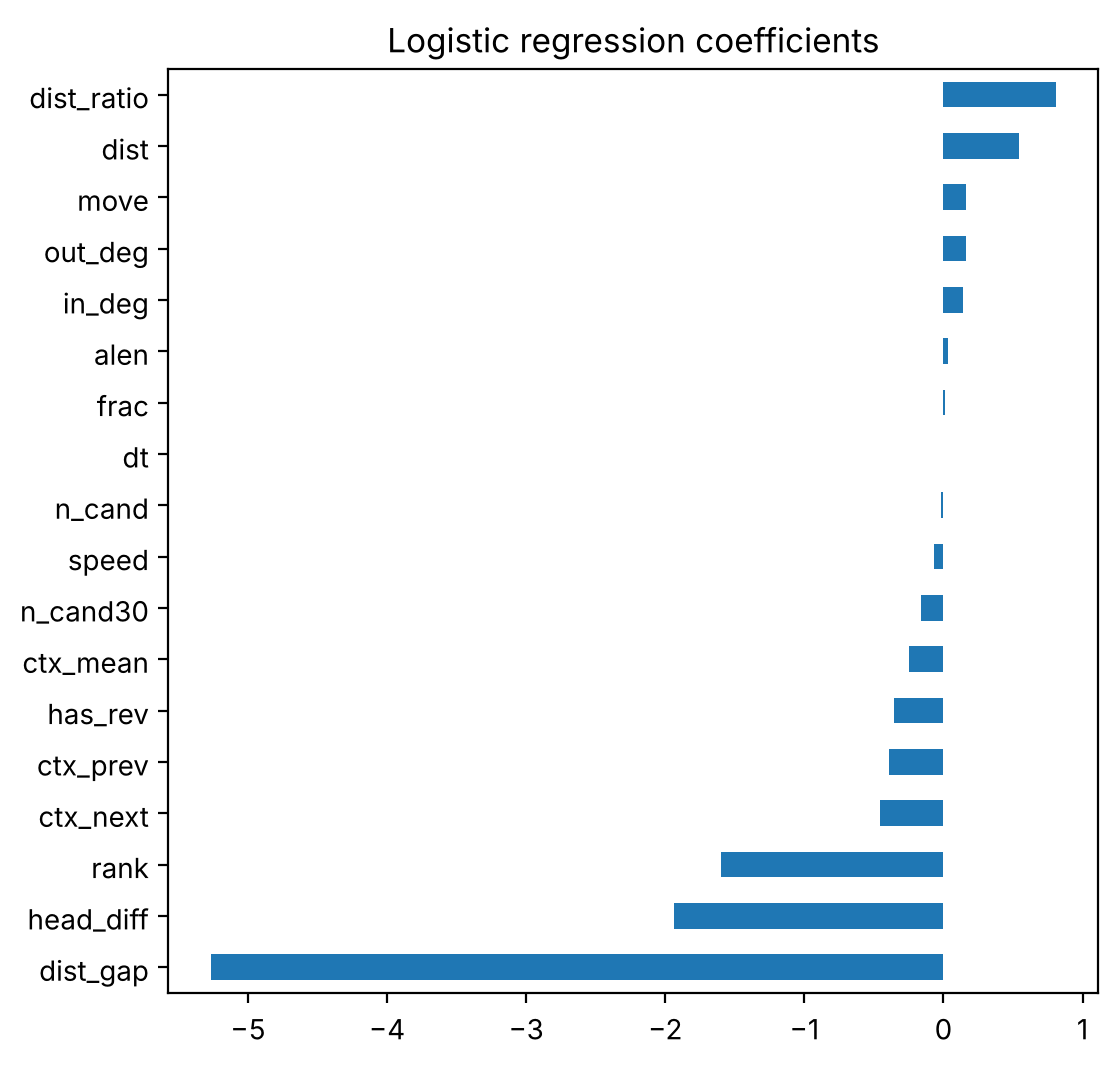

In [4]:
lr = modeling.joblib.load("../artifacts/models/M1_logreg.joblib")[-1]
pd.Series(lr.coef_[0], index=modeling.FEATURES).sort_values().plot.barh(figsize=(6, 6), title="Logistic regression coefficients")